# 03 · Sparse Autoencoder

**Arsitektur:** sama persis dengan Vanilla AE (784 → **256** → 64 → 256 → 784).

**Loss:** L = (1/D) ‖x − x̂‖² + **λ ‖h‖₁**, dengan h = aktivasi hidden layer 256 unit.

> **Ide utama (loss → visual):**
> Penalti λ‖h‖₁ "mendenda" setiap neuron yang menyala. Akibatnya, untuk setiap gambar **hanya sedikit neuron yang aktif**, dan setiap neuron terpaksa belajar **satu pola lokal yang spesifik** (misalnya bentuk kerah, sol sepatu, atau tali tas), bukan pola campuran yang menyebar.
> Harga yang dibayar: kapasitas yang dipakai untuk rekonstruksi berkurang, sehingga **MSE biasanya sedikit lebih buruk** dibanding Vanilla AE. Ruang latennya juga tetap tidak diatur, jadi *latent voids* tetap ada.

In [1]:
%run ./00_helpers.ipynb

device = cuda | dataset = fashion_mnist | QUICK = False
folder proyek = c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN
hasil -> c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results
Helpers siap ✔


c:\Users\Derry\Anaconda\envs\deep-learning\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load Dataset

In [2]:
set_seed()
splits = load_splits()
loaders = make_loaders(splits)
x_train, y_train = splits["train"]
x_test, y_test = splits["test"]

Jumlah data: {'train': 56000, 'val': 7000, 'test': 7000}


## 2. Hyperparameter

In [3]:
HIDDEN_DIM = 256          # lapisan "sparse" (diberi penalti L1)
LATENT_DIM = 64           # bottleneck
MAX_EPOCHS = n_epochs(30)
LEARNING_RATE = 1e-3
SPARSE_LAMBDA = 3e-5      # lambda pada lambda * ||h||_1 (1e-4 terbukti terlalu besar: >90% neuron mati)

## 3. Model

In [4]:
class AutoEncoder(nn.Module):
    # Encoder: x (784) -> h = ReLU(W1 x) (256) -> z = ReLU(W2 h) (64)
    # Decoder: z (64)  -> ReLU (256) -> Sigmoid (784)
    def __init__(self, hidden=256, latent=64):
        super().__init__()
        self.enc1 = nn.Linear(IMG_SIZE, hidden)
        self.enc2 = nn.Linear(hidden, latent)
        self.decoder = nn.Sequential(
            nn.Linear(latent, hidden), nn.ReLU(),
            nn.Linear(hidden, IMG_SIZE), nn.Sigmoid())

    def encode(self, x, return_hidden=False):
        h = F.relu(self.enc1(x.flatten(1)))
        z = F.relu(self.enc2(h))
        return (z, h) if return_hidden else z

    def decode(self, z):
        return self.decoder(z).view(-1, *IMG_SHAPE)

    def forward(self, x):
        z, h = self.encode(x, return_hidden=True)
        return self.decode(z), z, h

model = AutoEncoder(HIDDEN_DIM, LATENT_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(model)
print("Jumlah parameter:", count_params(model))

AutoEncoder(
  (enc1): Linear(in_features=784, out_features=256, bias=True)
  (enc2): Linear(in_features=256, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)
Jumlah parameter: 435536


## 4. Loss Function

In [5]:
def loss_fn(model, x):
    x_hat, z, h = model(x)
    mse = F.mse_loss(x_hat, x)
    l1 = h.abs().sum(dim=1).mean()             # ||h||_1 rata-rata per sampel
    loss = mse + SPARSE_LAMBDA * l1
    active = (h > 1e-3).float().mean().item()  # proporsi neuron yang menyala
    return loss, {"loss": loss.item(), "mse": mse.item(), "l1": l1.item(), "active_frac": active}

## 5. Training

In [6]:
history = {"model": "sparse_ae", "params": count_params(model), "epoch": [], "iter_loss": [],
           "epoch_time_s": [], "train": [], "val": []}

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    t0 = time.perf_counter()
    sums, n = {}, 0
    for it, (x, _) in enumerate(loaders["train"]):
        x = x.to(device)
        loss, logs = loss_fn(model, x)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        for k, v in logs.items():
            sums[k] = sums.get(k, 0.0) + v
        n += 1
        if it % 10 == 0:
            history["iter_loss"].append(logs["loss"])
    sync()
    history["epoch_time_s"].append(time.perf_counter() - t0)
    history["train"].append({k: v / n for k, v in sums.items()})

    # validasi
    model.eval()
    vsums, vn = {}, 0
    with torch.no_grad():
        for x, _ in loaders["val"]:
            _, logs = loss_fn(model, x.to(device))
            for k, v in logs.items():
                vsums[k] = vsums.get(k, 0.0) + v
            vn += 1
    history["val"].append({k: v / vn for k, v in vsums.items()})
    history["epoch"].append(epoch)
    tr = history["train"][-1]
    print(f"Epoch[{epoch}/{MAX_EPOCHS}] " + "  ".join(f"{k}: {v:.4f}" for k, v in tr.items())
          + f"  | val loss: {history['val'][-1]['loss']:.4f}  ({history['epoch_time_s'][-1]:.1f}s)")

torch.save({"model": model.state_dict()}, CKPT_DIR / "sparse_ae.pt")

Epoch[1/30] loss: 0.0382  mse: 0.0366  l1: 52.1637  active_frac: 0.1739  | val loss: 0.0223  (1.4s)
Epoch[2/30] loss: 0.0197  mse: 0.0187  l1: 31.3695  active_frac: 0.1372  | val loss: 0.0181  (1.2s)
Epoch[3/30] loss: 0.0168  mse: 0.0159  l1: 28.0554  active_frac: 0.1386  | val loss: 0.0160  (1.3s)
Epoch[4/30] loss: 0.0152  mse: 0.0144  l1: 26.3961  active_frac: 0.1417  | val loss: 0.0148  (1.3s)
Epoch[5/30] loss: 0.0142  mse: 0.0135  l1: 25.4287  active_frac: 0.1445  | val loss: 0.0141  (1.2s)
Epoch[6/30] loss: 0.0135  mse: 0.0128  l1: 24.8369  active_frac: 0.1478  | val loss: 0.0136  (1.2s)
Epoch[7/30] loss: 0.0130  mse: 0.0122  l1: 24.3965  active_frac: 0.1507  | val loss: 0.0130  (1.2s)
Epoch[8/30] loss: 0.0125  mse: 0.0118  l1: 24.0611  active_frac: 0.1532  | val loss: 0.0127  (1.2s)
Epoch[9/30] loss: 0.0121  mse: 0.0114  l1: 23.6130  active_frac: 0.1549  | val loss: 0.0122  (1.2s)
Epoch[10/30] loss: 0.0118  mse: 0.0111  l1: 23.3561  active_frac: 0.1568  | val loss: 0.0120  (1.2s)

## 6. Plot Loss History

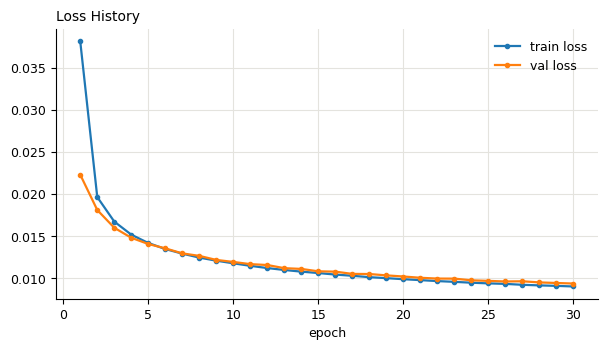

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(history["epoch"], [e["loss"] for e in history["train"]], "-o", ms=3, label="train loss")
ax.plot(history["epoch"], [e["loss"] for e in history["val"]], "-o", ms=3, label="val loss")
ax.set_title("Loss History", loc="left"); ax.set_xlabel("epoch"); ax.legend()
plt.show()

## 7. Evaluasi pada Test Set

- **Metrik rekonstruksi:** MSE, PSNR, SSIM pada seluruh Test Set.
- **Latency:** waktu encode + decode untuk 64 citra uji dan untuk 1 citra.

In [8]:
model.eval()
recon_fn = lambda x: model(x)[0]

metrics = {"model": "sparse_ae", "params": count_params(model), "latent_dim": LATENT_DIM,
           "train_time_per_epoch_s": float(np.mean(history["epoch_time_s"]))}
metrics.update(reconstruction_metrics(recon_fn, x_test))

x64, x1 = x_test[:LATENCY_BATCH].to(device), x_test[:1].to(device)
metrics["latency_ms_batch64"], metrics["latency_ms_batch64_std"] = measure_latency(lambda: recon_fn(x64))
metrics["latency_ms_batch1"], metrics["latency_ms_batch1_std"] = measure_latency(lambda: recon_fn(x1))
metrics["latency_mode"] = "rekonstruksi (encode + decode)"

print(f"Test MSE  : {metrics['mse']:.5f}")
print(f"Test PSNR : {metrics['psnr']:.2f} dB")
print(f"Test SSIM : {metrics['ssim']:.4f}")
print(f"Latency   : {metrics['latency_ms_batch64']:.2f} ms / batch 64 | {metrics['latency_ms_batch1']:.2f} ms / 1 sampel")

Test MSE  : 0.00872
Test PSNR : 21.63 dB
Test SSIM : 0.7337
Latency   : 0.30 ms / batch 64 | 0.30 ms / 1 sampel


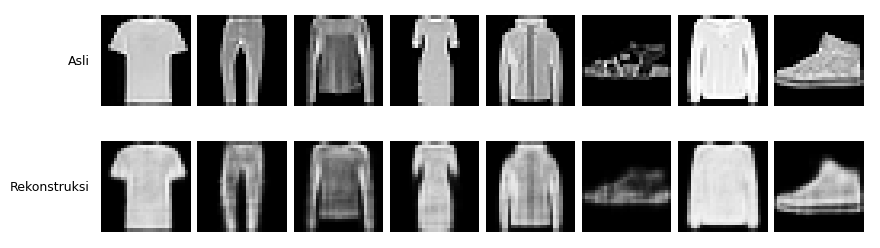

In [9]:
# Visual: baris atas = citra asli, baris bawah = rekonstruksi
x_fix, y_fix = fixed_examples(splits)
with torch.no_grad():
    recon_fix = recon_fn(x_fix.to(device)).cpu()
fig, axes = plt.subplots(2, 1, figsize=(10, 3))
show_imgs(axes[0], x_fix, label="Asli")
show_imgs(axes[1], recon_fix, label="Rekonstruksi")
plt.show()

## 8. Analisis Tambahan untuk Pertanyaan Penelitian

### 8a. Struktur fitur hidden layer (Q2)
Berapa persen dari 256 neuron hidden yang menyala untuk setiap gambar? Bagaimana bentuk filter W1-nya?

{'active_frac_mean': 0.1907011866569519, 'active_units_per_sample': 48.81950378417969, 'dead_units': 150, 'l1_per_sample': 20.225934982299805}


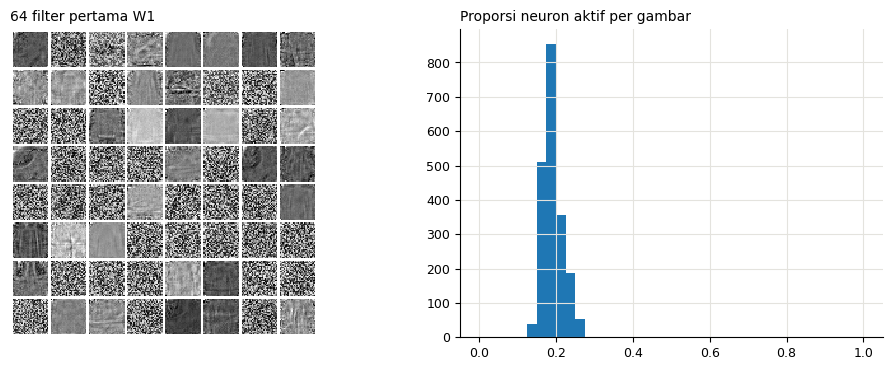

In [10]:
with torch.no_grad():
    _, h_test = model.encode(x_test[:2000].to(device), return_hidden=True)
act = (h_test > 1e-3).float()
sparsity = {"active_frac_mean": float(act.mean()),
            "active_units_per_sample": float(act.sum(1).mean()),
            "dead_units": int((act.sum(0) == 0).sum()),
            "l1_per_sample": float(h_test.abs().sum(1).mean())}
active_frac_per_image = act.mean(1).cpu()
W1_filters = model.enc1.weight[:64].detach().cpu().view(64, 1, 28, 28)
W1_filters = (W1_filters - W1_filters.amin((1, 2, 3), keepdim=True)) / (
    W1_filters.amax((1, 2, 3), keepdim=True) - W1_filters.amin((1, 2, 3), keepdim=True) + 1e-8)
print(sparsity)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
show_imgs(axes[0], W1_filters, nrow=8, title="64 filter pertama W1")
axes[1].hist(active_frac_per_image.numpy(), bins=40, range=(0, 1))
axes[1].set_title("Proporsi neuron aktif per gambar", loc="left")
plt.show()

### 8b. Deteksi anomali dengan reconstruction error (Q6 bagian 1)

In [11]:
anomaly = anomaly_auroc(recon_fn, x_test)
print(anomaly)

{'auroc': 0.7243547857142857, 'err_normal_mean': 0.008722003549337387, 'err_defect_mean': 0.01368654053658247, 'err_ratio': 1.5691968202590942}


### 8d. Interpolasi laten (Figur 4 & Q4)
z_A = kode laten citra uji kelas A, z_B = kode laten citra uji kelas B. `bank` = kode laten 5.000 data latih, dipakai untuk mendeteksi *latent voids*.

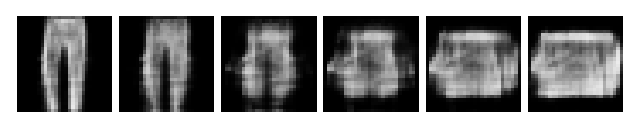

{'model': 'sparse_ae', 'alpha': 0.0, 'nn_dist_ratio': 1.2235660552978516, 'classifier_max_conf': 0.9999998807907104, 'pixel_change_from_prev': 0.0}
{'model': 'sparse_ae', 'alpha': 0.2, 'nn_dist_ratio': 1.3030261993408203, 'classifier_max_conf': 0.9985364675521851, 'pixel_change_from_prev': 0.049351416528224945}
{'model': 'sparse_ae', 'alpha': 0.4, 'nn_dist_ratio': 1.4645555019378662, 'classifier_max_conf': 0.6957700848579407, 'pixel_change_from_prev': 0.06404002010822296}
{'model': 'sparse_ae', 'alpha': 0.6, 'nn_dist_ratio': 1.4257935285568237, 'classifier_max_conf': 0.5258855223655701, 'pixel_change_from_prev': 0.07337353378534317}
{'model': 'sparse_ae', 'alpha': 0.8, 'nn_dist_ratio': 1.2589317560195923, 'classifier_max_conf': 0.9989035129547119, 'pixel_change_from_prev': 0.09430541843175888}
{'model': 'sparse_ae', 'alpha': 1.0, 'nn_dist_ratio': 1.3283318281173706, 'classifier_max_conf': 0.9999922513961792, 'pixel_change_from_prev': 0.07653461396694183}


In [12]:
clf = load_mlp_classifier()
xa, xb = interp_endpoints(splits)
enc = model.encode
with torch.no_grad():
    za, zb = enc(xa.to(device)), enc(xb.to(device))
    bank = apply_batched(enc, x_train[:5000]).to(device)
interp_imgs, interp_rows = interpolation_record("sparse_ae", za, zb, model.decode, clf, bank)
fig, ax = plt.subplots(figsize=(8, 1.6)); show_imgs(ax, interp_imgs); plt.show()
for r in interp_rows:
    print(r)

### 8e. Uji sampling acak di ruang laten AE (Q4)
Autoencoder deterministik **tidak punya prior**. Coba ambil z ~ N(μ_z, diag σ_z²) dari statistik kode laten citra uji, lalu decode. Karena ruang latennya penuh "lubang", hasilnya biasanya rusak. Inilah sebabnya FID untuk AE ditulis *N/A (Latent Voids)* di tabel.

{'frac_negative_entries': 0.03388437628746033, 'frac_zero_entries_real': 0.061745535582304, 'fid': 173.02367643568795, 'mode_coverage': {'class_hist': [0.13979999721050262, 0.0142000000923872, 0.1103999987244606, 0.10239999741315842, 0.12359999865293503, 0.05779999867081642, 0.17159999907016754, 0.06880000233650208, 0.18639999628067017, 0.02500000037252903], 'entropy_norm': 0.9238553047180176, 'modes_covered': 9}}


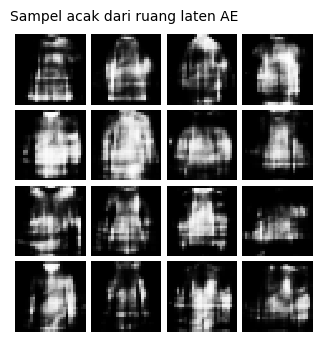

In [13]:
with torch.no_grad():
    z_test = apply_batched(model.encode, x_test)
z_rand, zstats = gaussian_fit_sampling(z_test, FID_NUM_SAMPLES)
samples = apply_batched(model.decode, z_rand)
gauss_fit = {**zstats, "fid": compute_fid(samples, splits), "mode_coverage": mode_coverage(samples, clf)}
print(gauss_fit)
fig, ax = plt.subplots(figsize=(4, 4)); show_imgs(ax, samples[:16], nrow=4, title="Sampel acak dari ruang laten AE"); plt.show()

### 8f. Pengaruh nilai λ terhadap fidelitas rekonstruksi (Q1)
Model kecil dilatih ulang **sebentar** dengan beberapa nilai λ (λ = 0 sama dengan Vanilla AE). Polanya: **makin besar λ → makin sedikit neuron aktif → rekonstruksi makin buruk (MSE naik)**.

> 💡 **Cara memilih λ untuk model utama:** kalau di bagian 8a neuron aktif per gambar sangat sedikit (misalnya < 3%) atau hampir semua neuron "mati", berarti λ terlalu besar. Kecilkan `SPARSE_LAMBDA` di bagian 2, lalu jalankan ulang notebook ini.

{'lambda': 0.0, 'mse': 0.012713420204818249, 'ssim': 0.6553490684858306, 'active_frac_mean': 0.521066427230835}
{'lambda': 1e-05, 'mse': 0.012468974106013775, 'ssim': 0.6575549284754818, 'active_frac_mean': 0.24824415147304535}
{'lambda': 3e-05, 'mse': 0.013207405805587769, 'ssim': 0.6404157618023417, 'active_frac_mean': 0.1421504020690918}
{'lambda': 0.0001, 'mse': 0.017934953793883324, 'ssim': 0.5703547628655282, 'active_frac_mean': 0.03812304884195328}
{'lambda': 0.001, 'mse': 0.03006351739168167, 'ssim': 0.4268780034440585, 'active_frac_mean': 0.012468750588595867}


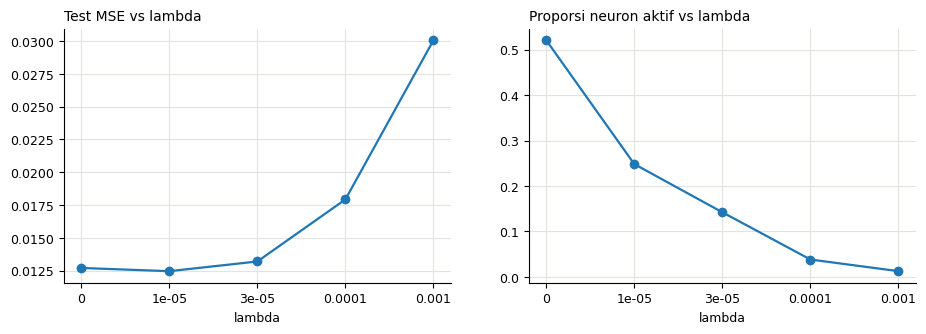

In [14]:
RUN_LAMBDA_SWEEP = True
SWEEP_LAMBDAS = [0.0, 1e-5, 3e-5, 1e-4, 1e-3]
SWEEP_EPOCHS = n_epochs(5)
lambda_sweep = []
if RUN_LAMBDA_SWEEP:
    for lam in SWEEP_LAMBDAS:
        set_seed()
        m = AutoEncoder(HIDDEN_DIM, LATENT_DIM).to(device)
        o = torch.optim.Adam(m.parameters(), lr=LEARNING_RATE)
        for _ in range(SWEEP_EPOCHS):
            m.train()
            for x, _ in loaders["train"]:
                x = x.to(device)
                x_hat, z, h = m(x)
                loss = F.mse_loss(x_hat, x) + lam * h.abs().sum(1).mean()
                o.zero_grad(); loss.backward(); o.step()
        m.eval()
        r = reconstruction_metrics(lambda x: m(x)[0], x_test)
        with torch.no_grad():
            _, hh = m.encode(x_test[:2000].to(device), return_hidden=True)
        lambda_sweep.append({"lambda": lam, "mse": r["mse"], "ssim": r["ssim"],
                             "active_frac_mean": float((hh > 1e-3).float().mean())})
        print(lambda_sweep[-1])

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
    labels = [f"{l:g}" for l in SWEEP_LAMBDAS]
    axes[0].plot(labels, [r["mse"] for r in lambda_sweep], "-o"); axes[0].set_title("Test MSE vs lambda", loc="left")
    axes[1].plot(labels, [r["active_frac_mean"] for r in lambda_sweep], "-o"); axes[1].set_title("Proporsi neuron aktif vs lambda", loc="left")
    for ax in axes:
        ax.set_xlabel("lambda")
    plt.show()

## 9. Simpan Hasil untuk Laporan

In [15]:
metrics["stability"] = stability_summary(history)
metrics["anomaly"] = anomaly
metrics["hparams"] = {"epochs": len(history["epoch"]), "lr": LEARNING_RATE, "batch_size": BATCH_SIZE,
                      "hidden_dim": HIDDEN_DIM, "latent_dim": LATENT_DIM}
metrics["sparsity"] = sparsity
metrics["gaussian_fit_sampling"] = gauss_fit
metrics["lambda_sweep"] = lambda_sweep
metrics["hparams"]["sparse_lambda"] = SPARSE_LAMBDA
save_results("sparse_ae", metrics, artifacts={"recon_fixed": recon_fix, "x_fixed": x_fix, "interp_imgs": interp_imgs, "interp_rows": interp_rows, "W1_filters": W1_filters, "active_frac_per_image": active_frac_per_image}, history=history)

Hasil 'sparse_ae' tersimpan di c:\Users\Derry\OneDrive - Bina Nusantara\Documents\BINUS\Semester 5\Deep Learning LEC\Tugas AE dan GAN\results/
